# Study 2: the Study 1 model under three knowledge regimes

Study 2 (KnowQA) tests the correctness model on readers whose knowledge we control. Six participants came for three sessions each and answered 870 multiple-choice questions in all, each under one of three regimes: **no knowledge** (no context at all, so a correct answer is a guess), **partial knowledge** (the paragraph to read, as in Study 1) and **full knowledge** (they are first shown the correct answer's content, reworded). After every answer they rated their confidence from 1 to 5. The notebook describes the data by regime, fits the model on all of Study 1 and applies it to every Study 2 trial, scores it on each regime separately, and sets its predicted probability of a correct answer against the confidence rating. Six people are too few for any comparison between people, so the per-person figures show patterns, not tests. Every participant did all three regimes, so splitting by regime splits each person's trials rather than separating people. The model keeps Study 1's scaling: every feature is standardised with Study 1's means and SDs. This notebook only shows; it saves nothing.

In [1]:
import sys
from pathlib import Path
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "__init__.py").exists())
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
from src.lib.plotting.output import set_output_defaults
set_output_defaults(save=False)   # this notebook only shows; it saves nothing

import contextlib
import io

import matplotlib.pyplot as plt
import pandas as pd

from src.config.datasets import dataset, KNOW_QA_IA_ANSWERS_PATH
from src.features.build import load_model_ready
import src.analyses.correctness_prediction.knowledge_regimes.descriptives as D
from src.analyses.correctness_prediction.knowledge_regimes.comparison_runs import (
    run_regime_split_comparison,
)
from src.analyses.correctness_prediction.knowledge_regimes.confidence_correlation import (
    correlations_by_participant,
    run_confidence_correlation,
)

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)

# Study 2's tables, named once and passed to every call: `comparison_runs` and
# `confidence_correlation` default to the first pilot (3 people), not to KnowQA.
KNOWQA_FEATURES = dataset("knowqa").model_ready    # one row per trial
KNOWQA_IA_REPORT = KNOW_QA_IA_ANSWERS_PATH         # cleaned IA report: regime, session, confidence
l1 = load_model_ready(dataset("l1").model_ready)   # Study 1, the training data

print("KnowQA features: ", KNOWQA_FEATURES.relative_to(ROOT))
print("KnowQA IA report:", KNOWQA_IA_REPORT.relative_to(ROOT))
print(f"Study 1: {len(l1):,} trials\n")

df = D.load_showcase_frame(KNOWQA_FEATURES, KNOWQA_IA_REPORT)

KnowQA features:  data\datasets\knowqa\features\model_ready.csv
KnowQA IA report: data_raw\KnowQA\csvs\cleaned\IA_answers.csv
Study 1: 19,436 trials



KnowQA showcase frame: 870 trials x 201 columns
  participants : 6
  sessions     : 18
  regimes      : {'no knowledge': 300, 'full knowledge': 294, 'partial knowledge': 276}


## 1. The data by regime (`descriptives`)

`load_showcase_frame` reads KnowQA's trial table and adds three columns from the cleaned IA report: the regime, the session and the confidence rating. It stops if any trial gets no regime, since such a trial would drop out of every per-regime table while still counting in the pooled one. Below, one row per participant: sessions, trials, and trials in each regime.

In [2]:
D.cohort_summary(df)

,participant_id,sessions,trials,no knowledge,partial knowledge,full knowledge
0,4000,3,145,50,46,49
1,4001,3,145,50,46,49
2,4002,3,145,50,46,49
3,4003,3,145,50,46,49
4,4004,3,145,50,46,49
5,4005,3,145,50,46,49


### How often the participants were right

The share of correct answers in each regime, with 95% intervals; the dotted line is chance (1 in 4). The no-knowledge rate is the empirical guess rate: how far above 1 in 4 a guess actually lands. Each person contributes to every bar.

,regime,n,n_correct,accuracy,ci_low,ci_high
0,all,870,633,0.728,0.697,0.756
1,no knowledge,300,126,0.420,0.366,0.477
2,partial knowledge,276,223,0.808,0.757,0.850
3,full knowledge,294,284,0.966,0.939,0.981


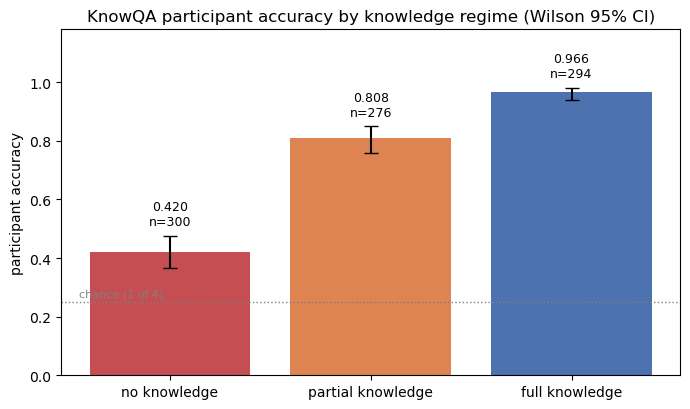

In [3]:
acc = D.correctness_by_regime(df)
display(acc.round(3))
D.plot_accuracy_by_regime(acc, save=False);

### How fast they went

KnowQA has no paragraph screen, so every measure is about the answer screen: the question and the four options. `total answering time` runs from the options appearing to the confirming press; the `ms per word` measures divide time by the number of words on screen; `area transitions` counts moves between the five areas. The table shows the means; the figure adds standard-error whiskers, one panel per measure because their scales differ.

regime,all,no knowledge,partial knowledge,full knowledge
label,,,,
area transitions in the trial,8.4,10.1,8.6,6.3
ms per word on screen,302.1,393.5,324.6,187.8
"ms per word, correct answer",519.7,551.6,618.6,394.2
"ms per word, question",128.5,230.0,110.0,42.4
"ms per word, wrong answers (mean)",370.1,471.6,413.4,225.7
selection presses before confirming,1.5,1.7,1.4,1.3
total answering time (ms),11471.0,14969.3,11982.0,7421.6


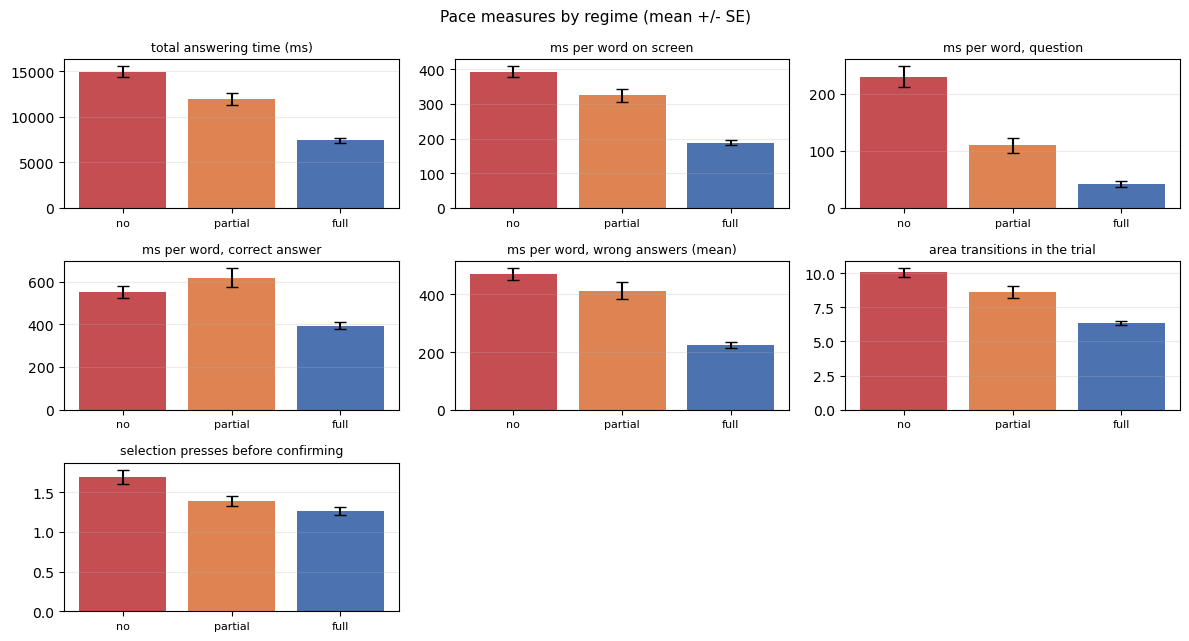

In [4]:
pace = D.reading_speed_by_regime(df)
display(pace.pivot(index="label", columns="regime", values="mean")
            .reindex(columns=["all", *D.REGIME_ORDER]).round(1))
D.plot_pace_panel(df, save=False);

The means hide how wide each regime's spread is. Below, the full distribution for three of the measures: total answering time, the same time per word on screen, and the number of fixation runs between areas (`seq_len`). Outliers are not drawn.

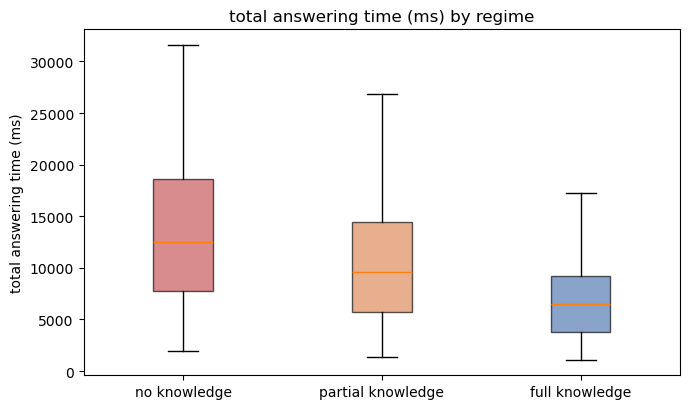

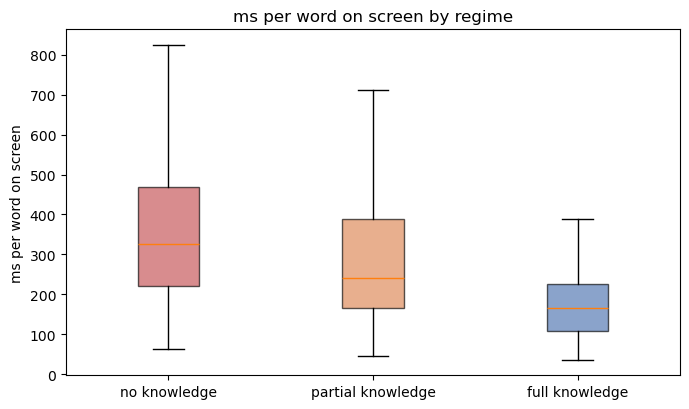

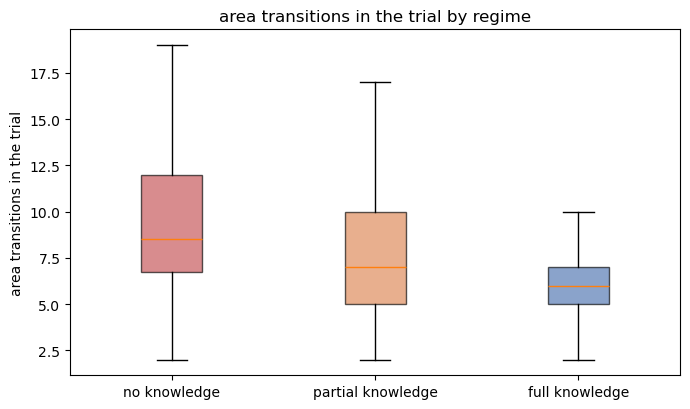

In [5]:
for measure in ["total_answering_RT", "total_answering_RT_normalized", "seq_len"]:
    D.plot_pace_by_regime(df, measure, save=False)
plt.show()

### How confident they said they were

Mean confidence (1 to 5) per regime, split by whether the answer was right. The gap between a regime's two bars is how well the participants could tell, in that regime, when they were wrong.

,regime,n,mean_confidence,n_correct,mean_confidence_correct,n_wrong,mean_confidence_wrong
0,all,870,3.44,633,3.96,237,2.04
1,no knowledge,300,1.76,126,1.87,174,1.68
2,partial knowledge,276,3.83,223,4.06,53,2.85
3,full knowledge,294,4.78,284,4.80,10,4.00


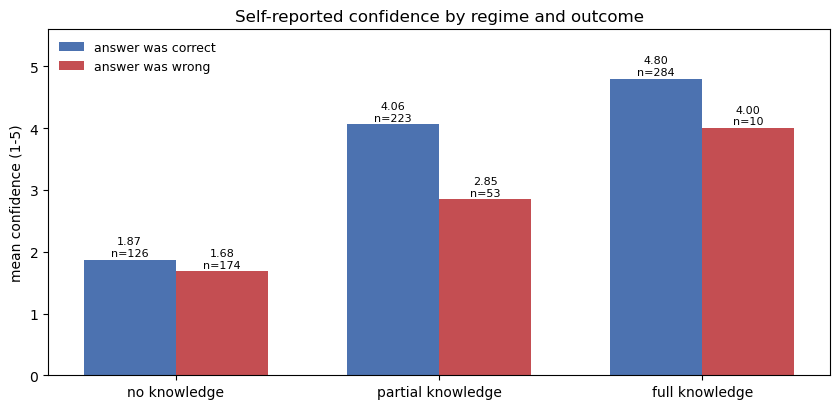

In [6]:
conf = D.confidence_by_regime(df)
display(conf.round(2))
D.plot_confidence_by_regime(conf, save=False);

How often each rating was used, as a share of the regime's trials (each row sums to 1). A rating used rarely in a regime makes any mean at that rating rest on few trials.

confidence_rating,regime,1,2,3,4,5
0,no knowledge,0.500,0.313,0.127,0.043,0.017
1,partial knowledge,0.029,0.112,0.170,0.377,0.312
2,full knowledge,0.000,0.003,0.031,0.153,0.813


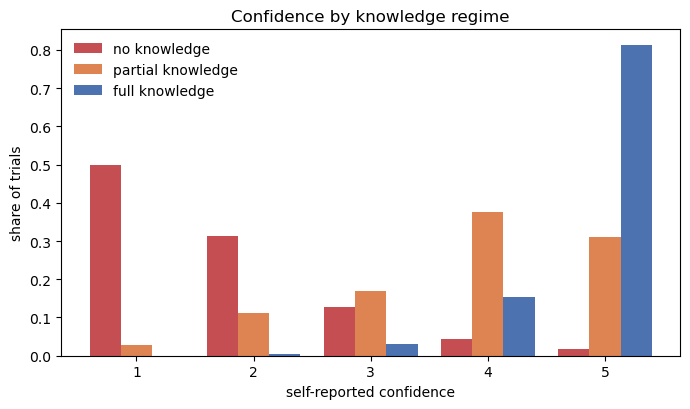

In [7]:
dist = D.confidence_distribution(df)
display(dist.round(3))
D.plot_confidence_distribution(df, save=False);

### The Study 1 model, fitted once and applied to every trial

`fit_l1_model` fits the correctness model (a logistic regression) on every Study 1 trial, with nothing held out, on 12 features: ten hand-picked features of how the answers were looked at and selected, plus whether the last area looked at before confirming was the correct answer and whether it was the question. `attach_predictions` then adds, to every KnowQA trial, the model's predicted probability that the answer is correct (`pred_prob`) and its predicted label. It first prints how many feature cells the model fills with 0 because they are empty (a pupil size exists only where the person fixated); that fill is a stated modelling choice, not a measurement. Two things the numbers below do not show: every feature is standardised with Study 1's mean and SD, so a feature that runs higher in KnowQA appears shifted; and KnowQA's pupil baseline pools each person's three sessions.

In [8]:
model = D.fit_l1_model(l1)
df = D.attach_predictions(df, model)

fitted trial_level_log_reg on 19436 L1 trials, 12 features
  L1 base rate: 0.8407
imputed with fill_value=0.0: 10 cell(s) = 0.096% of the KnowQA feature matrix
    mean_max_fix_pupil_size_z__correct: 10 (1.15% of trials)


### How well it transfers

One row per regime, after all trials pooled. Read `balanced_accuracy` (the mean of sensitivity and specificity), not `accuracy`: the share of correct answers runs from 0.42 under no knowledge to 0.97 under full knowledge, and plain accuracy largely repeats it. In the figure the dashed line is that share, the score of always predicting "correct". The model is trained to weigh both outcomes equally, so it gives up some accuracy on the common outcome to catch the rare one. Under full knowledge there are only ten wrong answers, so its specificity rests on very few trials.

,regime,n,n_correct,n_wrong,accuracy,balanced_accuracy,sensitivity,specificity,TP,TN,FP,FN,FN_over_FP
0,all,870,633,237,0.786,0.824,0.741,0.907,469,215,22,164,7.455
1,no knowledge,300,126,174,0.827,0.811,0.714,0.908,90,158,16,36,2.250
2,partial knowledge,276,223,53,0.725,0.794,0.682,0.906,152,48,5,71,14.200
3,full knowledge,294,284,10,0.803,0.850,0.799,0.900,227,9,1,57,57.000


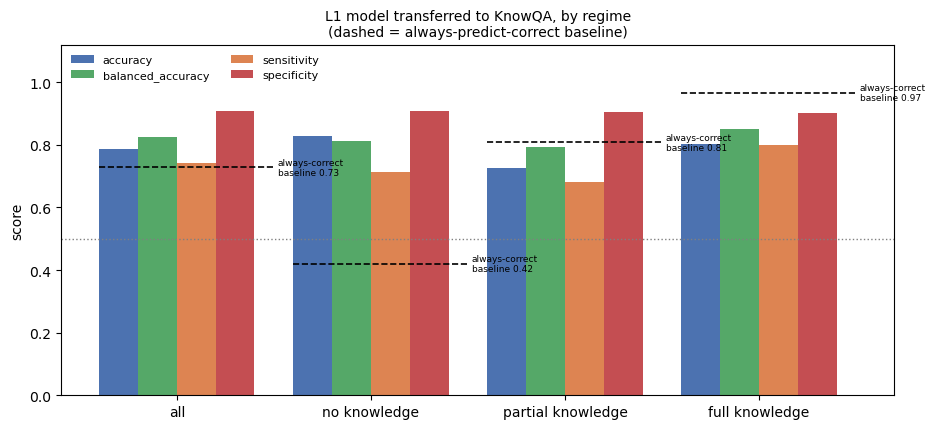

In [9]:
metrics = D.prediction_metrics_by_regime(df)
display(metrics.round(3))
D.plot_transfer_metrics(metrics, save=False);

One confusion matrix per regime, shaded by the share of each actual outcome, with the counts printed. The top-left share is the specificity (wrong answers predicted wrong), the bottom-right the sensitivity (correct answers predicted correct).

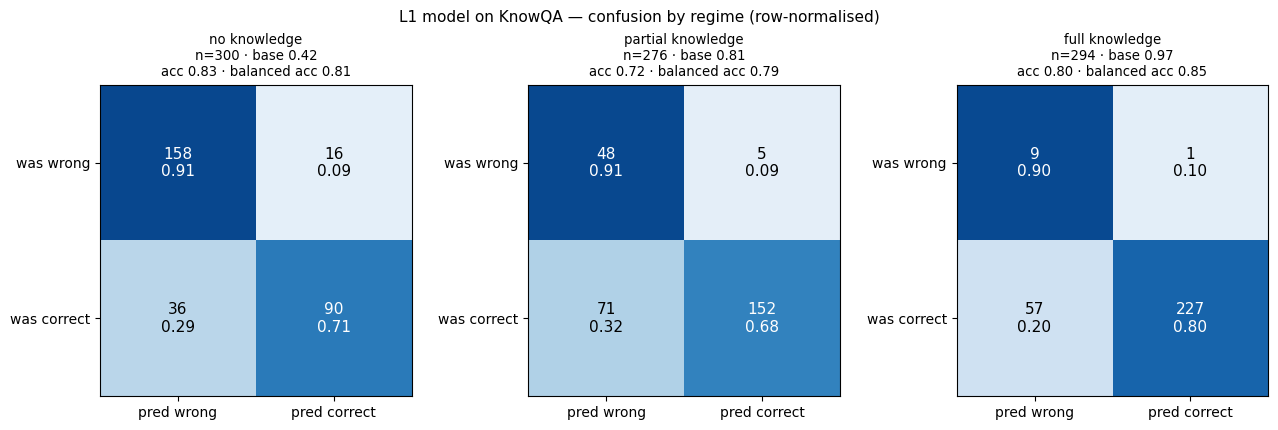

In [10]:
D.plot_confusion_by_regime(df, save=False);

### What probabilities it gives

The study's central prediction: high probabilities under full knowledge, low under no knowledge, *including* on the no-knowledge answers that happened to be right, because the model reads behaviour rather than the outcome. Compare the boxes for correct answers across regimes: lucky guesses should sit lower than correct answers given with full knowledge. `mean_prob_correct` in the table is the same comparison in numbers.

,regime,n,mean_prob,median_prob,sd_prob,n_correct,mean_prob_correct,n_wrong,mean_prob_wrong
0,all,870,0.561,0.644,0.359,633,0.703,237,0.182
1,no knowledge,300,0.388,0.271,0.345,126,0.666,174,0.187
2,partial knowledge,276,0.570,0.651,0.346,223,0.665,53,0.168
3,full knowledge,294,0.730,0.876,0.298,284,0.749,10,0.182


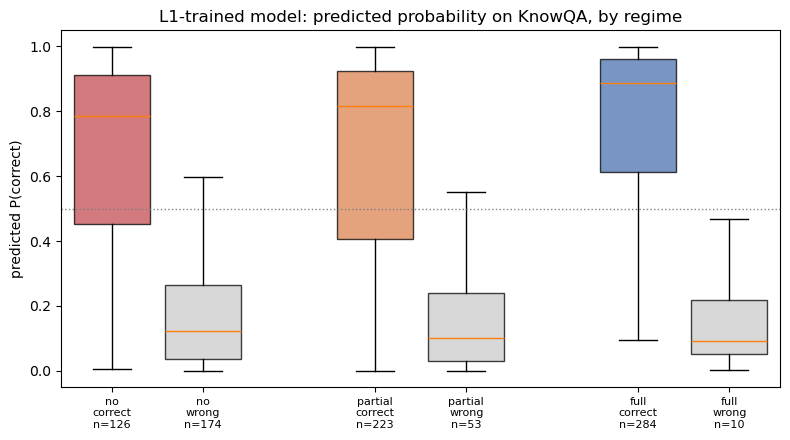

In [11]:
display(D.probability_by_regime(df).round(3))
D.plot_probability_by_regime(df, save=False);

The same probabilities as histograms, one panel per regime, split into correct and wrong answers; the dashed line is the regime's mean. Where the two humps sit apart, the model separates right from wrong *within* the regime, not only by following its share of correct answers.

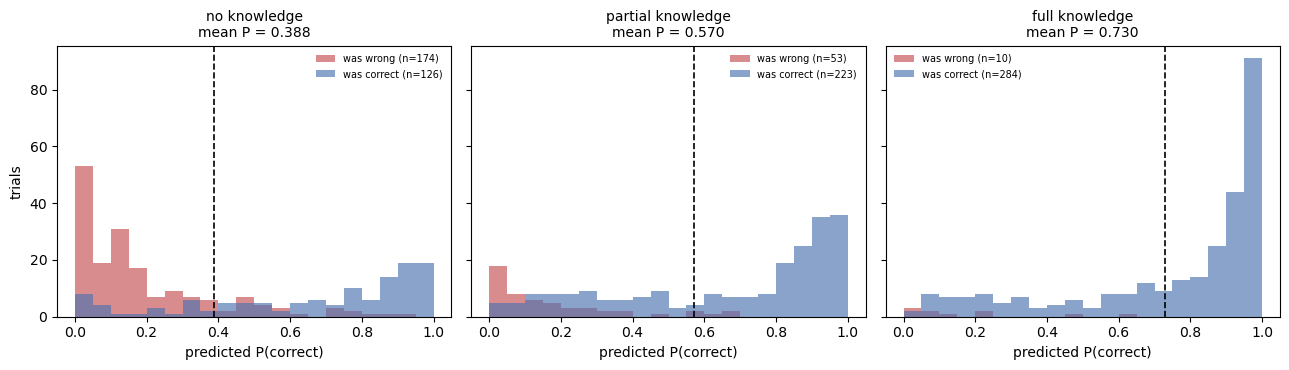

In [12]:
D.plot_probability_histograms(df, save=False);

### The model against the confidence rating

Which tells right from wrong answers apart better, the model or the participant's own rating? Both are scored the same way, by the AUC for predicting a correct answer, on the same trials. `auc_combined` averages the two ranks: if it beats both, they carry different information. The curves show where the difference comes from. Under full knowledge the AUCs rest on ten wrong answers.

,regime,n,n_correct,auc_model,auc_confidence,auc_combined,model_minus_confidence
0,all,870,633,0.904,0.841,0.940,0.063
1,no knowledge,300,126,0.875,0.562,0.812,0.313
2,partial knowledge,276,223,0.902,0.804,0.919,0.098
3,full knowledge,294,284,0.928,0.774,0.926,0.154


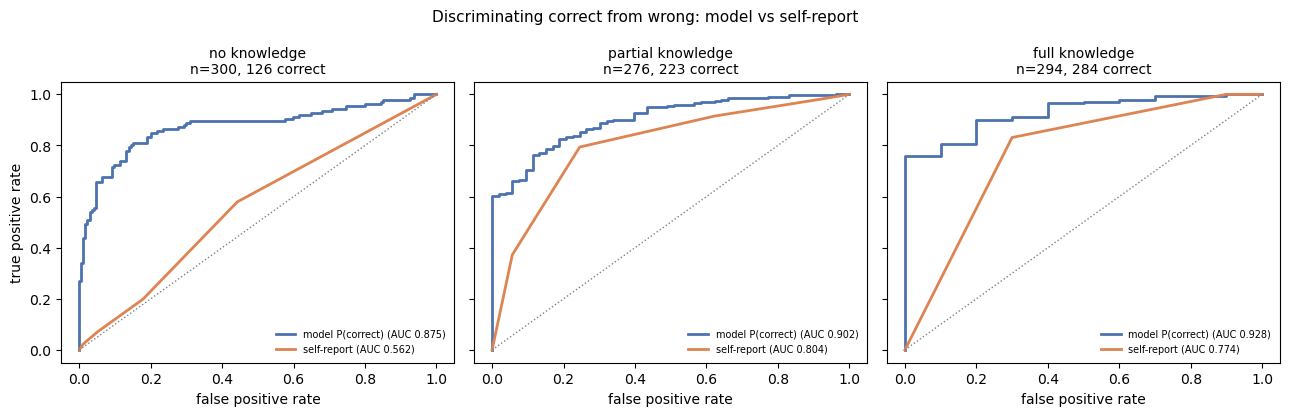

In [13]:
display(D.discrimination_comparison(df).round(3))
D.plot_discrimination_roc(df, save=False);

### Per participant

Six people: enough to see a pattern (is someone low everywhere, or in one regime only?), not to test one. The heatmap shows, per participant and regime, their own accuracy, their mean confidence, the model's mean predicted probability and the model's balanced accuracy. Where a participant made no errors in a regime, balanced accuracy is undefined, and the cell shows the model's plain accuracy with a star. The narrow left panel is each participant's English proficiency score (LexTALE, 0 to 100), entered by hand in the module; the table gives it beside their accuracy. With six points, no relation between the two can be tested.

,participant_id,lextale,n,participant_accuracy,no knowledge,partial knowledge,full knowledge,n_participants
0,4000,93.75,145.0,0.779,0.50,0.848,1.000,NaN
1,4001,88.75,145.0,0.772,0.50,0.848,0.980,NaN
2,4002,91.25,145.0,0.745,0.42,0.848,0.980,NaN
3,4003,81.25,145.0,0.724,0.38,0.848,0.959,NaN
4,4004,75.00,145.0,0.676,0.32,0.783,0.939,NaN
5,4005,95.00,145.0,0.669,0.40,0.674,0.939,NaN
6,mean,87.50,145.0,0.728,0.42,0.808,0.966,6.0


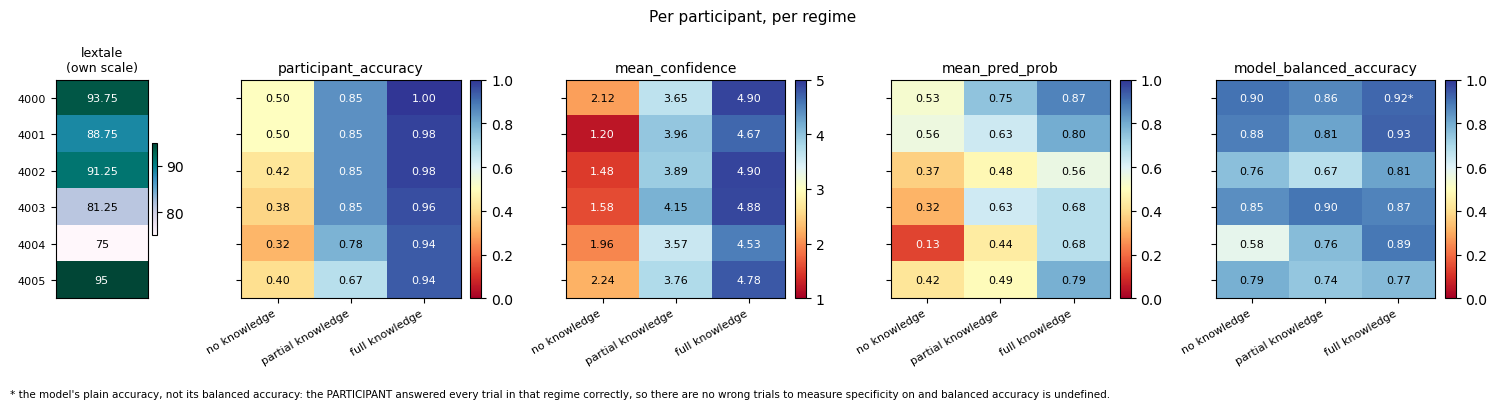

In [14]:
df = D.attach_lextale(df)
display(D.lextale_summary(df).round(3))
D.plot_participant_regime_heatmap(df, side_column="lextale", figsize=(15, 3.8), save=False);

The same per-participant numbers as lines, one per regime, so the shape reads at a glance: is someone low everywhere, or in one regime only, and do their confidence and the model's probability move together?

,participant_id,regime,n,n_wrong,participant_accuracy,mean_confidence,median_RT_ms,mean_seq_len,mean_pred_prob,model_accuracy,model_balanced_accuracy,model_sensitivity,model_specificity,auc_model,auc_confidence
0,4000,full knowledge,49,0,1.000,4.898,2729.0,5.286,0.874,0.918,NaN,0.918,NaN,NaN,NaN
1,4000,no knowledge,50,25,0.500,2.120,6379.0,8.060,0.531,0.900,0.900,0.880,0.920,0.968,0.706
2,4000,partial knowledge,46,7,0.848,3.652,4231.5,7.196,0.747,0.870,0.864,0.872,0.857,0.949,0.835
3,4001,full knowledge,49,1,0.980,4.673,5395.0,5.878,0.800,0.857,0.927,0.854,1.000,0.938,0.844
4,4001,no knowledge,50,25,0.500,1.200,12432.0,9.340,0.558,0.880,0.880,0.920,0.840,0.938,0.540
5,4001,partial knowledge,46,7,0.848,3.957,9768.0,7.978,0.633,0.783,0.813,0.769,0.857,0.941,0.780
6,4002,full knowledge,49,1,0.980,4.898,8867.0,5.816,0.564,0.633,0.812,0.625,1.000,0.958,0.469
7,4002,no knowledge,50,29,0.420,1.480,12139.0,7.380,0.370,0.780,0.758,0.619,0.897,0.806,0.484
8,4002,partial knowledge,46,7,0.848,3.891,11766.0,7.826,0.478,0.543,0.672,0.487,0.857,0.810,0.800
9,4003,full knowledge,49,2,0.959,4.878,8349.0,7.041,0.675,0.755,0.872,0.745,1.000,0.957,0.957


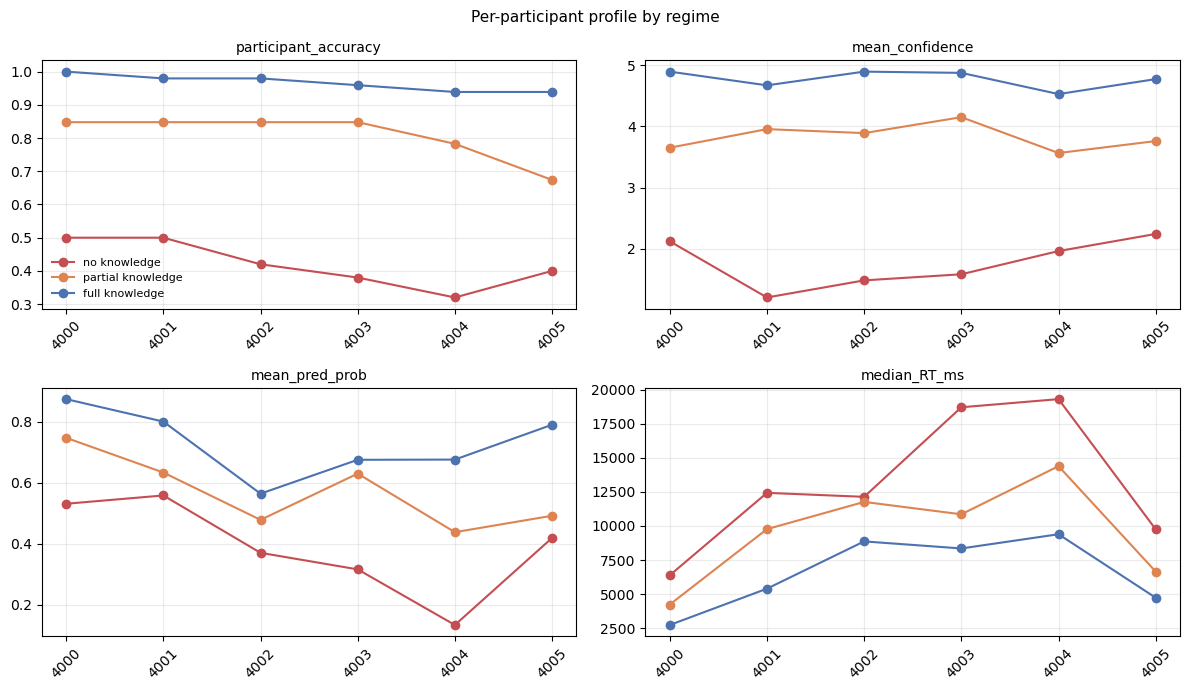

In [15]:
display(D.participant_profile(df).round(3))
D.plot_participant_profiles(df, save=False);

LexTALE on its own. Left: each participant's score against the group mean. Right: score against accuracy, one series per regime plus all trials. The correlations below have six points each; read them as description, not as tests.

,regime,n_participants,spearman_r,p_value
0,all,6,0.086,0.872
1,no knowledge,6,0.551,0.257
2,partial knowledge,6,-0.169,0.749
3,full knowledge,6,0.265,0.612


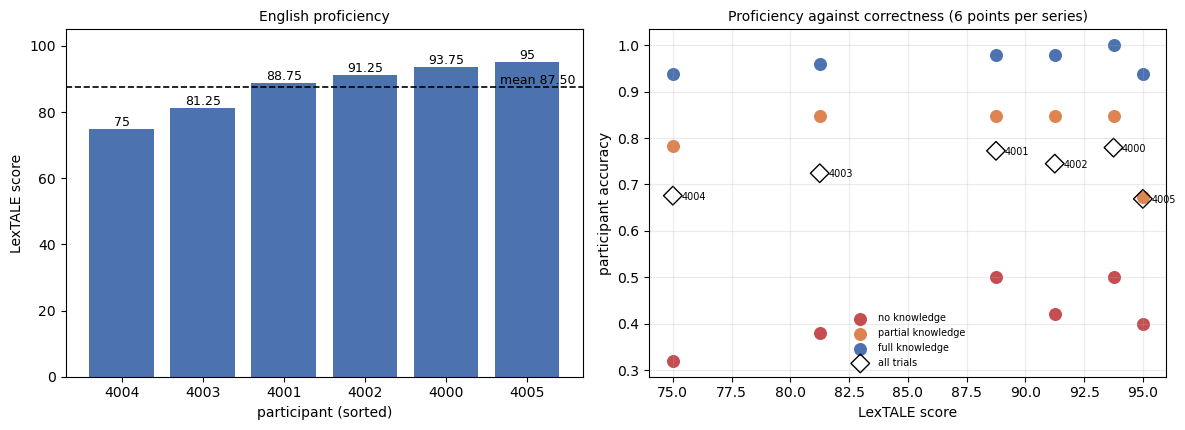

In [16]:
display(D.lextale_correlations(df).round(3))
D.plot_lextale(df);

### Across the three sittings

**Read the confound first.** Every participant took the three article batches in the same order, and the batches share no items, so a change across sittings may come from the people (tiring, practice) or from the items (later batches harder), and these data cannot tell which. As a partial check, every KnowQA item also appears in Study 1, where it was answered with no sittings at all: its Study 1 accuracy (`l1_item_acc`) is a difficulty baseline, drawn beside the participants' accuracy in the left panel.

The tests below all respect that the trials are nested in six people. The two regressions are the informative pair: the second adds item difficulty, so watch what the sitting coefficient does when it enters. With six pairs, the Wilcoxon test cannot go below p = 0.031, however large the effect.

,session,n,n_items,participant_accuracy,l1_item_acc,mean_confidence,model_balanced_accuracy,model_auc,mean_pred_prob,confidence_auc
0,1,282,141,0.762,0.855,3.723,0.846,0.920,0.585,0.819
1,2,300,150,0.730,0.822,3.367,0.822,0.906,0.554,0.863
2,3,288,144,0.691,0.806,3.229,0.806,0.888,0.545,0.834


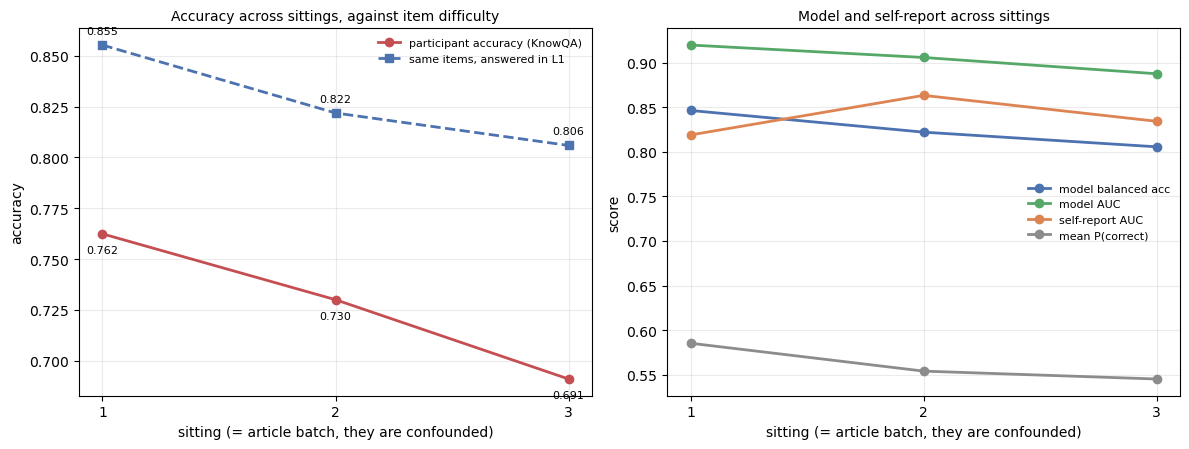

In [17]:
df = D.attach_item_difficulty(D.add_session_order(df), l1)
display(D.session_summary(df).round(3))
D.plot_session_trend(df, save=False);

In [18]:
D.session_trend_tests(df).round(4)

,test,n_units,statistic,p_value,effect,effect_is
0,"Wilcoxon, sitting 1 vs 3",6,4.0000,0.2188,-0.0714,mean accuracy difference
1,"per-participant Spearman(sitting, correct), vs 0",6,-1.5016,0.1935,-0.0669,mean within-participant rho
2,clustered logit: sitting + regime,6,0.8476,0.3598,-0.1653,log-odds per sitting (statistic = odds ratio)
3,clustered logit: sitting + regime + item diffi...,6,0.8894,0.5418,-0.1173,log-odds per sitting (statistic = odds ratio)


Each participant across their three sittings, one line per person. A time that falls steadily from sitting to sitting is practice with the interface, not a response to the regimes.

,participant_id,session_id,n,n_wrong,participant_accuracy,mean_confidence,median_RT_ms,mean_seq_len,mean_pred_prob,model_accuracy,model_balanced_accuracy,model_sensitivity,model_specificity,auc_model,auc_confidence
0,4000,4000_11,47,8,0.830,3.851,4567.0,7.745,0.729,0.894,0.886,0.897,0.875,0.942,0.902
1,4000,4000_21,50,13,0.740,3.660,3836.0,6.700,0.701,0.880,0.869,0.892,0.846,0.956,0.918
2,4000,4000_31,48,11,0.771,3.125,3545.0,6.125,0.717,0.917,0.946,0.892,1.000,0.998,0.894
3,4001,4001_12,47,9,0.809,3.447,11254.0,7.745,0.664,0.809,0.839,0.789,0.889,0.845,0.886
4,4001,4001_22,50,13,0.740,3.140,8721.0,7.820,0.644,0.900,0.907,0.892,0.923,0.960,0.862
5,4001,4001_32,48,11,0.771,3.167,6470.0,7.646,0.684,0.812,0.783,0.838,0.727,0.912,0.763
6,4002,4002_13,47,8,0.830,3.745,11094.0,7.000,0.568,0.723,0.784,0.692,0.875,0.853,0.801
7,4002,4002_23,50,11,0.780,3.220,10354.0,7.280,0.424,0.580,0.698,0.487,0.909,0.741,0.823
8,4002,4002_33,48,18,0.625,3.250,9156.5,6.688,0.422,0.667,0.711,0.533,0.889,0.819,0.817
9,4003,4003_14,47,9,0.809,3.574,12982.0,8.468,0.620,0.851,0.908,0.816,1.000,0.971,0.735


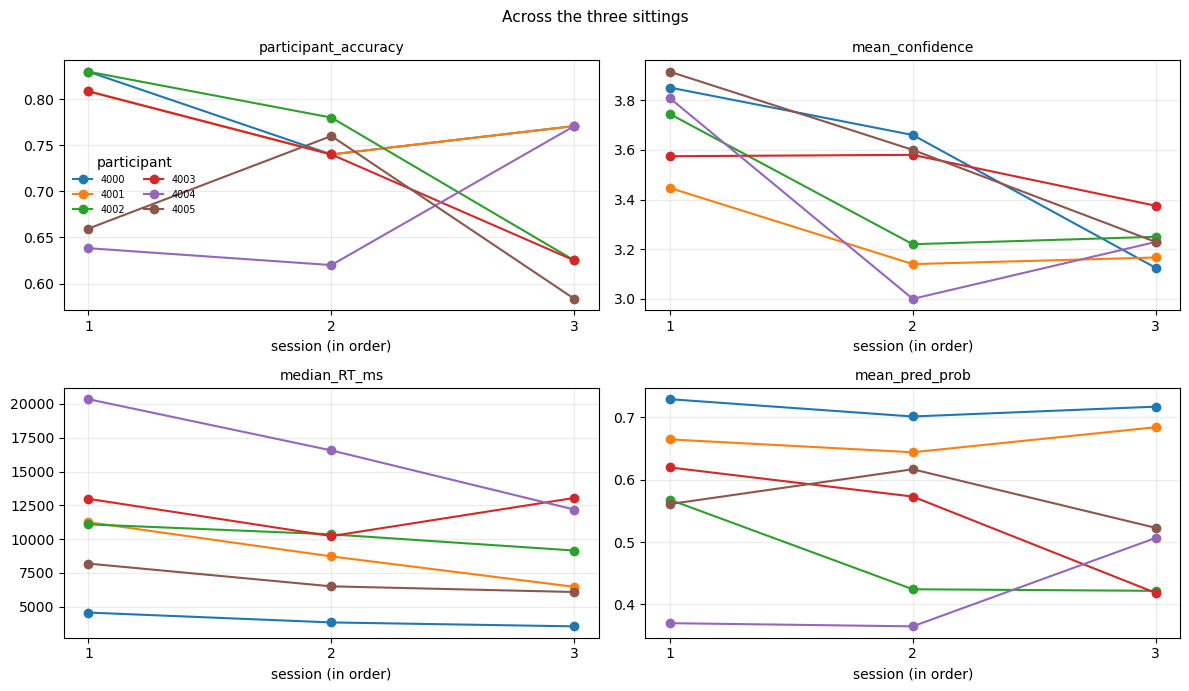

In [19]:
display(D.participant_profile(df, by=(D.SESSION_COL,)).round(3))
D.plot_session_trajectories(df, save=False);

## 2. The Study 1 model scored on each regime as a separate run (`comparison_runs`)

`run_regime_split_comparison` fits the model on all of Study 1 and scores it on the KnowQA trials of each regime in turn, and on all of them pooled (`all`), through the project's standard train-on-Study-1, test-on-new-data routine. Every run fits the same model on the same data, so the runs differ only in the trials they are scored on.

It uses the same 12 features as section 1 (`D.SHOWCASE_FEATURE_COLS`, set once in `descriptives`), so its predictions are the same model's as section 1's.

KnowQA's feature table and IA report are passed explicitly, because this module's defaults point to the first pilot. `regimes=` only fixes the order of the rows. The routine draws six figures per run (24 in all: confusion matrices, a probability histogram, coefficient bars, a feature-correlation map) and prints a full score report per run; the figures are closed here and only the head of the printout is shown, to keep the notebook short.

In [20]:
log = io.StringIO()
with contextlib.redirect_stdout(log), plt.rc_context({"figure.max_open_warning": 0}):
    regime_result = run_regime_split_comparison(
        train_df=l1,
        new_features=KNOWQA_FEATURES,
        regime_source=KNOWQA_IA_REPORT,
        regimes=D.REGIME_ORDER,
        save=False,
    )
plt.close("all")   # the 24 figures the four runs drew; not shown here

lines = log.getvalue().splitlines()
print("\n".join(lines[:10]))
dropped = [line for line in lines if line.startswith("[cross-dataset]")]
print("\n".join(dropped) if dropped else "no feature dropped: KnowQA has all of the model's features")
print(f"\nfeatures the model used: {len(regime_result['outputs']['all']['feature_cols'])}")

train (L1): (19436, 219) | test (new): (870, 200)

new-data trials per regime:
regime
no knowledge         300
full knowledge       294
partial knowledge    276

regimes evaluated: ['no knowledge', 'partial knowledge', 'full knowledge']

no feature dropped: KnowQA has all of the model's features

features the model used: 12


One row per run. The share of correct answers (`n_positive / n_test`) differs a lot between regimes, so compare `balanced_accuracy` and `roc_auc` across rows rather than `accuracy`. `f1_class_0`, the F1 for wrong answers, rests on ten wrong answers under full knowledge.

In [21]:
regime_result["comparison"].round(3)

,regime,n_test,n_positive,n_negative,accuracy,balanced_accuracy,macro_f1,weighted_f1,f1_class_0,f1_class_1,roc_auc
0,all,870,633,237,0.786,0.824,0.766,0.797,0.698,0.835,0.904
1,no knowledge,300,126,174,0.827,0.811,0.817,0.824,0.859,0.776,0.875
2,partial knowledge,276,223,53,0.725,0.794,0.679,0.754,0.558,0.800,0.902
3,full knowledge,294,284,10,0.803,0.850,0.562,0.865,0.237,0.887,0.928


## 3. Confidence against the model's probability (`confidence_correlation`)

`run_confidence_correlation` takes the per-trial predictions of the section 2 runs (nothing is refitted) and adds each trial's confidence rating from KnowQA's IA report, passed explicitly because the default is the first pilot's. It asks three questions per run, which can disagree:

* **model vs confidence** (`pred_prob ~ confidence`): does the predicted probability rise with the rating? This is the headline.
* **confidence vs correctness** (`is_correct ~ confidence`): does the rating itself track being right? Without this reference a weak result for the model cannot be read, since the rating might simply be noise.
* **within participant**: confidence scales are personal (one person's "4" is another's "2"), so a pooled correlation mixes the effect inside each person with differences in how people use the scale. Correlations computed per participant keep only the first.

The pooled `all` run repeats every regime's trials, and the regimes differ a lot in both confidence and accuracy, so read the per-regime rows beside it. Below the table: predicted probability against confidence, one point per trial and one panel per run; the mean predicted probability at each rating, one line per run, with the participants' actual accuracy (all trials pooled) as a grey dashed line; and the spread of predicted probabilities at each rating. A point on a line can rest on a single trial (full knowledge at rating 2); the counts are in the table that follows.

,run,comparison,n,mean_x,mean_y,pearson_r,spearman_r,spearman_p
0,all,pred_prob ~ confidence,870,3.44,0.561,0.429,0.427,8.313195e-40
1,all,is_correct ~ confidence,870,3.44,0.728,0.553,0.546,7.124089e-69
2,no knowledge,pred_prob ~ confidence,300,1.76,0.388,0.078,0.060,2.995253e-01
3,no knowledge,is_correct ~ confidence,300,1.76,0.420,0.099,0.116,4.508516e-02
4,partial knowledge,pred_prob ~ confidence,276,3.83,0.570,0.359,0.315,8.913612e-08
5,partial knowledge,is_correct ~ confidence,276,3.83,0.808,0.443,0.435,3.676400e-14
6,full knowledge,pred_prob ~ confidence,294,4.78,0.730,0.184,0.142,1.497001e-02
7,full knowledge,is_correct ~ confidence,294,4.78,0.966,0.288,0.254,1.050605e-05


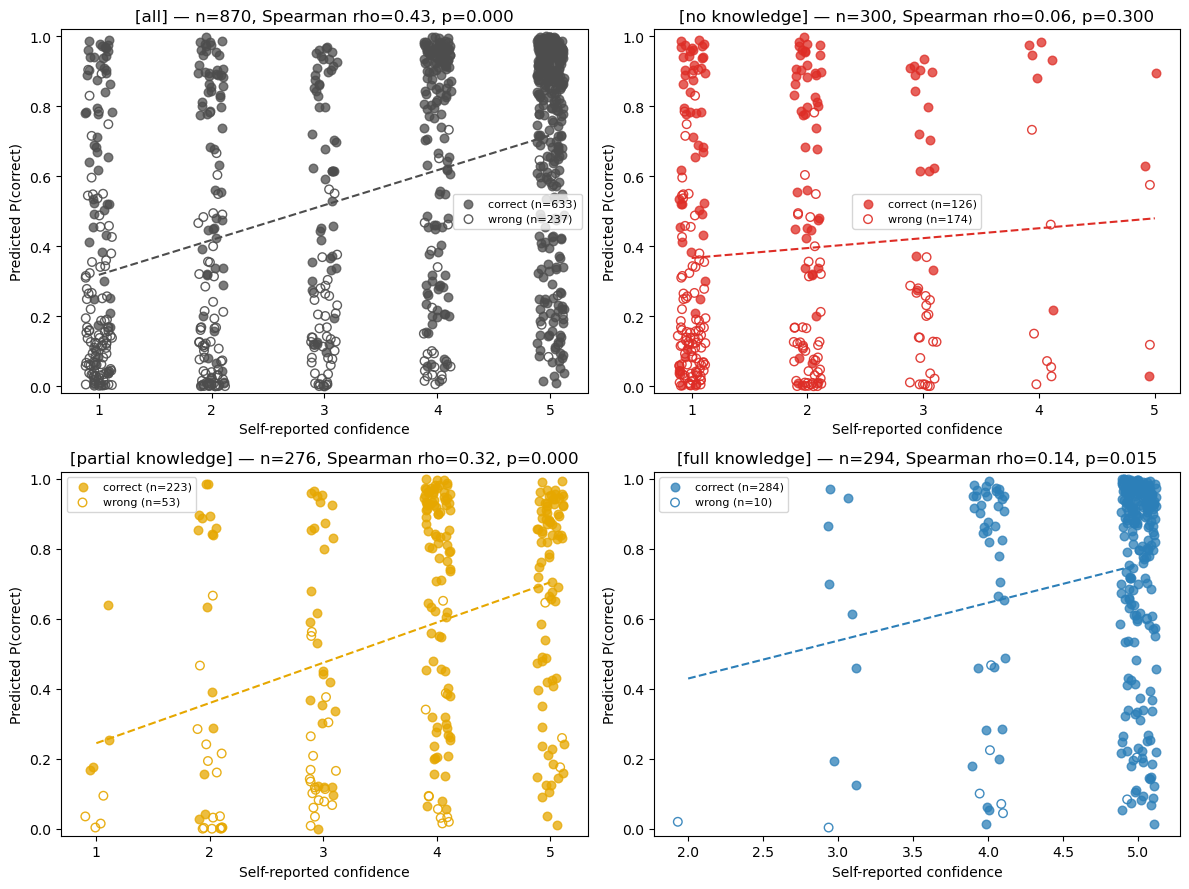

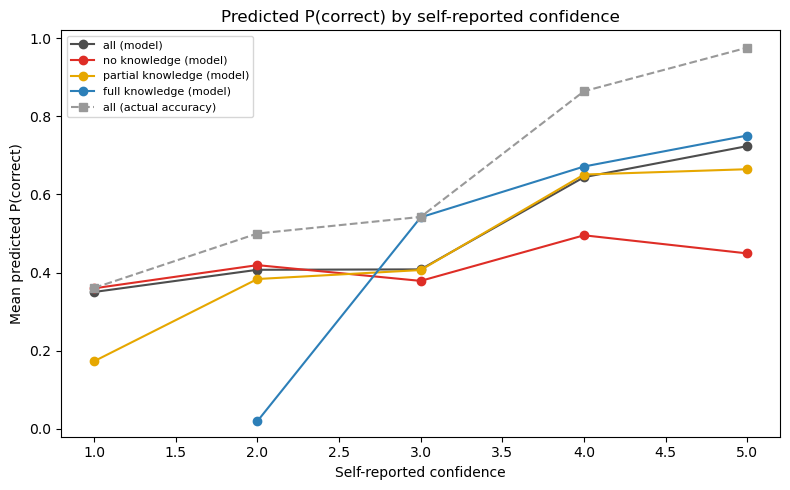

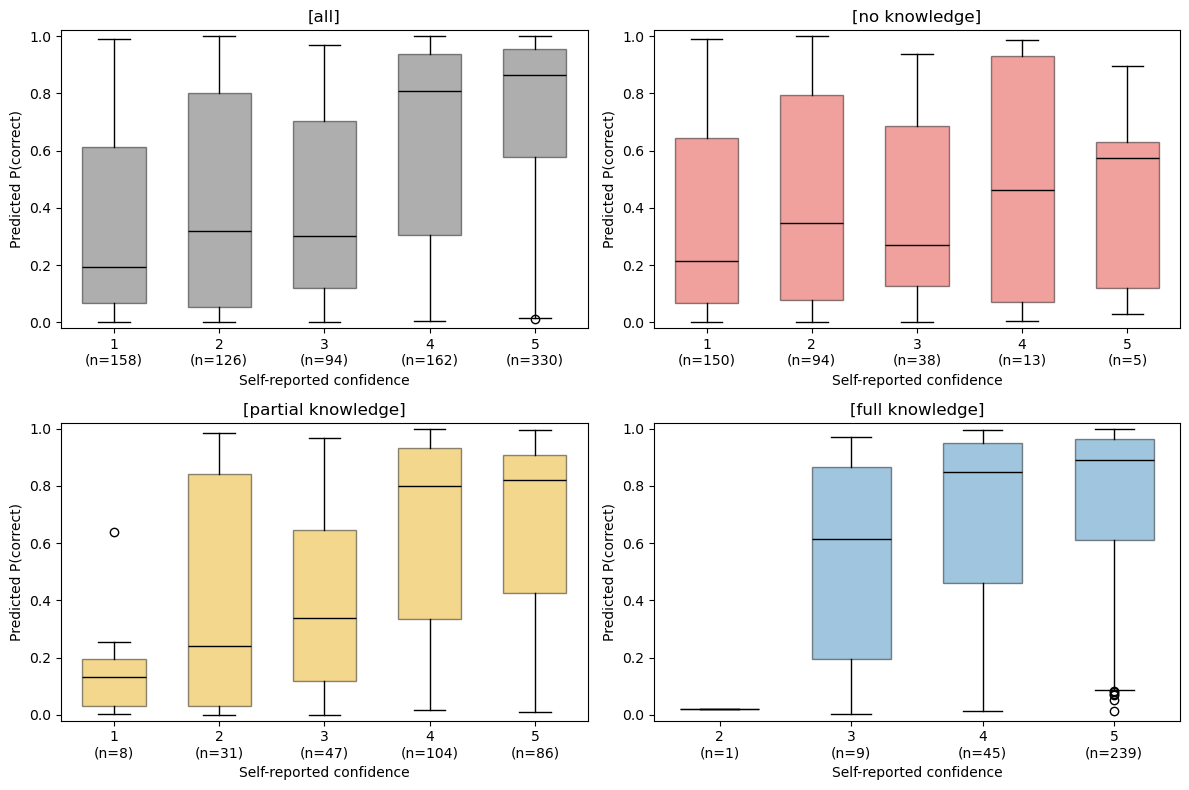

In [22]:
cc = run_confidence_correlation(
    regime_result,
    confidence_source=KNOWQA_IA_REPORT,
    save=False,
    verbose=False,
)
cols = ["run", "comparison", "n", "mean_x", "mean_y", "pearson_r", "spearman_r", "spearman_p"]
display(cc["correlations"][cols].round({"mean_x": 2, "mean_y": 3, "pearson_r": 3, "spearman_r": 3}))

The same correlations as bars (Spearman), one cluster per run, with significance stars. Read the two bars of a cluster together: where the rating itself does not track correctness (`is_correct ~ confidence` near zero), a weak bar for the model is not the model's failure.

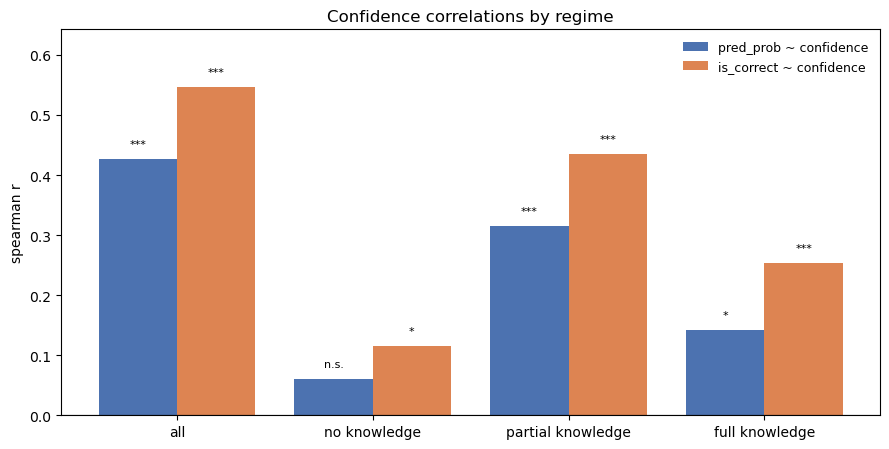

In [23]:
D.plot_correlations_by_run(cc["correlations"], save=False);

### At each confidence rating

Per run and rating: how many trials, the model's mean predicted probability, and the participants' actual accuracy. If the model tracks confidence, the two climb together down the scale. Ratings used rarely in a regime rest on few trials (`n`).

In [24]:
cc["by_confidence"].round(3)

,run,confidence_rating,n,mean_pred_prob,median_pred_prob,std_pred_prob,accuracy
0,all,1,158,0.350,0.193,0.330,0.361
1,all,2,126,0.407,0.320,0.362,0.500
2,all,3,94,0.408,0.303,0.331,0.543
3,all,4,162,0.644,0.809,0.339,0.864
4,all,5,330,0.724,0.864,0.291,0.976
5,no knowledge,1,150,0.360,0.214,0.333,0.353
6,no knowledge,2,94,0.419,0.345,0.358,0.511
7,no knowledge,3,38,0.379,0.271,0.331,0.421
8,no knowledge,4,13,0.495,0.462,0.418,0.462
9,no knowledge,5,5,0.449,0.575,0.365,0.600


### Within each participant

The same correlation, `pred_prob ~ confidence`, computed inside each person over all their trials. The p-values are per person and uncorrected, and six values are a small basis for the average.

In [25]:
by_person = cc["by_participant"]
cols = ["participant_id", "n", "mean_x", "mean_y", "pearson_r", "spearman_r", "spearman_p"]
display(by_person[cols].round({"mean_x": 2, "mean_y": 3, "pearson_r": 3, "spearman_r": 3}))
print(f"mean within-participant Spearman r: {by_person['spearman_r'].mean():.3f}")

,participant_id,n,mean_x,mean_y,pearson_r,spearman_r,spearman_p
0,4000,145,3.54,0.715,0.574,0.525,1.165957e-11
1,4001,145,3.25,0.664,0.306,0.281,6.308385e-04
2,4002,145,3.40,0.470,0.295,0.305,1.927092e-04
3,4003,145,3.51,0.537,0.497,0.525,1.275839e-11
4,4004,145,3.34,0.413,0.590,0.603,1.009419e-15
5,4005,145,3.58,0.567,0.463,0.494,2.752538e-10


mean within-participant Spearman r: 0.455


The within-participant correlations as a dot plot, with a second series: each person's rating against their own correctness. It shows whether the people whose rating tracks their correctness are also the ones the model agrees with.

,participant_id,n,mean_x,mean_y,pearson_r,spearman_r,spearman_p
0,4000,145,3.54,0.779,0.611,0.589,6.902906e-15
1,4001,145,3.25,0.772,0.528,0.513,4.294719e-11
2,4002,145,3.40,0.745,0.519,0.526,1.116708e-11
3,4003,145,3.51,0.724,0.596,0.592,4.162481e-15
4,4004,145,3.34,0.676,0.582,0.583,1.382506e-14
5,4005,145,3.58,0.669,0.549,0.552,6.419597e-13


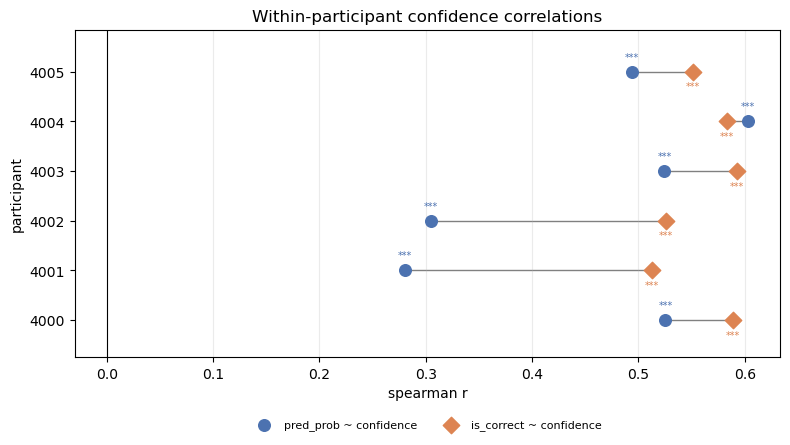

In [26]:
by_person_correct = correlations_by_participant(cc["predictions"], prob_col="is_correct")
display(by_person_correct[cols].round({"mean_x": 2, "mean_y": 3, "pearson_r": 3, "spearman_r": 3}))
D.plot_participant_correlation_forest(by_person, by_person_correct, save=False);